In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
!git clone https://github.com/Yosephines/IE7615-Group1-Project1.git

Cloning into 'IE7615-Group1-Project1'...
remote: Enumerating objects: 1618, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 1618 (delta 11), reused 18 (delta 7), pack-reused 1580 (from 1)
Receiving objects: 100% (1618/1618), 77.11 MiB | 15.91 MiB/s, done.
Resolving deltas: 100% (52/52), done.
Updating files: 100% (1439/1439), done.


In [4]:
REPO_DIR = Path("/content/IE7615-Group1-Project1")

DATA_DIR = REPO_DIR / "project_milestone02" / "dataset"

DATA_YAML = DATA_DIR / "data.yaml"

print("Dataset folder:", DATA_DIR)
print("Configuration file:", DATA_YAML)
print("Dataset found:", DATA_YAML.exists())

Dataset folder: /content/IE7615-Group1-Project1/project_milestone02/dataset
Configuration file: /content/IE7615-Group1-Project1/project_milestone02/dataset/data.yaml
Dataset found: True


In [5]:
for split in ["train", "val", "test"]:
    image_dir = DATA_DIR / split / "images"
    label_dir = DATA_DIR / split / "labels"

    images = list(image_dir.glob("*.jpg")) + list(image_dir.glob("*.png"))
    labels = list(label_dir.glob("*.txt"))

    print(split)
    print("Images:", len(images))
    print("Labels:", len(labels))
    print()

train
Images: 504
Labels: 504

val
Images: 36
Labels: 36

test
Images: 36
Labels: 36



In [6]:
model = YOLO("yolov8n.pt")

print("Pretrained YOLOv8 model loaded!")

Pretrained YOLOv8 model loaded!


In [7]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/Colab Notebooks/IE7615 - Deep Learning",
    name="milestone03_yolov8_baseline"
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/IE7615-Group1-Project1/project_milestone02/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=milestone03_yolov8_b

In [9]:
RUN_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/IE7615 - Deep Learning/milestone03_yolov8_baseline"
)

BEST_MODEL = RUN_DIR / "weights" / "best.pt"

print("Best model:", BEST_MODEL)
print("Model saved:", BEST_MODEL.exists())

Best model: /content/drive/MyDrive/Colab Notebooks/IE7615 - Deep Learning/milestone03_yolov8_baseline/weights/best.pt
Model saved: True


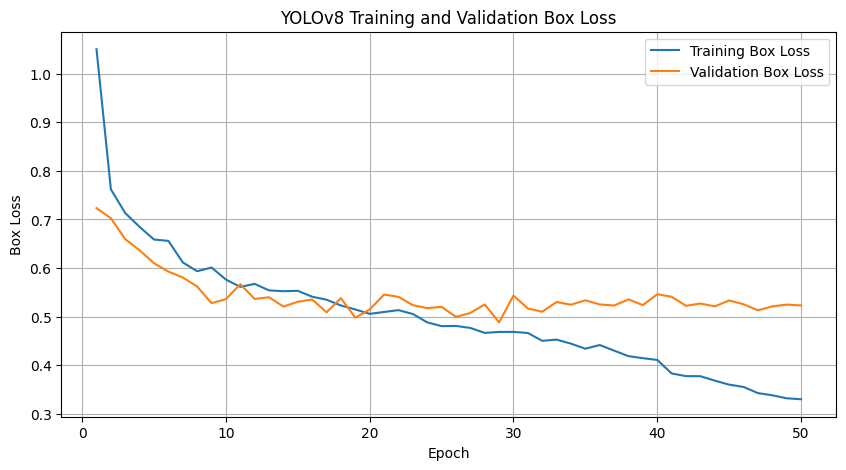

In [10]:
results_csv = RUN_DIR / "results.csv"

training_df = pd.read_csv(results_csv)

training_df.columns = training_df.columns.str.strip()

plt.figure(figsize=(10, 5))

plt.plot(training_df["epoch"], training_df["train/box_loss"], label="Training Box Loss")
plt.plot(training_df["epoch"], training_df["val/box_loss"], label="Validation Box Loss")

plt.xlabel("Epoch")
plt.ylabel("Box Loss")
plt.title("YOLOv8 Training and Validation Box Loss")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
trained_model = YOLO(str(BEST_MODEL))

print("Trained YOLOv8 model loaded successfully!")

Trained YOLOv8 model loaded successfully!


### YOLOv8 Fine-Tuning

A pretrained YOLOv8 Nano model was fine-tuned on the synthetic multi-celebrity dataset created in Milestone 2.

The dataset contains five celebrity identities and is organized into training, validation, and held-out test splits.

The initial training configuration used:
- Model: YOLOv8 Nano (`yolov8n.pt`)
- Epochs: 50
- Image size: 640
- Batch size: 8
- Random seed: 42
- Pretrained weights: Yes

The model was trained using the training split, while the validation split was used to monitor performance.

The best-performing checkpoint was saved as `best.pt`. Training logs and loss curves were also saved for evaluation and documentation.

### Training Results

The YOLOv8 Nano model successfully completed 50 training epochs on a Tesla T4 GPU in approximately 8.2 minutes.

The best checkpoint achieved the following results on the validation dataset:

- Precision: 0.916
- Recall: 0.905
- mAP@0.5: 0.972
- mAP@0.5:0.95: 0.868

Training losses generally decreased throughout training, indicating that the model learned from the synthetic dataset.

The best-performing model was saved as `best.pt` for subsequent evaluation, hyperparameter tuning, and demonstration.

These results are based on the validation set. Final held-out test performance will be evaluated separately.